# Crater Signature Analysis — REAL Australian Gravity + Magnetic Data

This notebook downloads **real** global gravity (XGM2019E) and magnetic (NGDC_720_V3)
models, samples them at the locations of known Australian impact craters, and tests
whether craters have a detectable potential-field signature distinct from random crust.

**No synthetic data.** Every number comes from real models fetched via `pyshtools`.

### What it does, step by step
1. Download the two global spherical-harmonic models (one-time, cached).
2. Convert each to a gravity-disturbance / magnetic-anomaly grid over Australia.
3. Sample features at the ~30 known craters and at random control locations.
4. Train a classifier and measure how well craters separate from controls,
   for all craters vs. only large (resolvable) ones.
5. Scan Australia for locations whose signature resembles known craters → candidates.

### Requirements
`pip install pyshtools scikit-learn numpy matplotlib`
The first run downloads ~100s of MB of model coefficients; later runs use the cache.
Needs internet access to the ICGEM / model servers (works on your machine; would fail
in a network-restricted sandbox).

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyshtools as pysh
import csv, io
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
print("pyshtools", pysh.__version__)

pyshtools 4.14.1


## 2. Known Australian craters (your catalog)

In [2]:
CSV = """name,lat,lon,diameter_km,status
Acraman,-32.1,135.1,90,confirmed
Amelia Creek,-20.55,134.50,20,confirmed
Boxhole,-22.37,135.12,0.17,confirmed
Cleanskin,-18.10,137.56,15,unconfirmed
Connolly Basin,-23.32,124.45,9,confirmed
Crawford,-34.43,139.2,8.5,confirmed
Dalgaranga,-27.38,117.17,0.02,confirmed
Flaxman,-34.37,139.4,10,confirmed
Foelsche,-15.40,136.47,6,confirmed
Glikson,-23.59,121.34,19,confirmed
Goat Paddock,-18.20,126.40,5.1,confirmed
Gosses Bluff,-23.49,132.19,22,confirmed
Goyder,-13.28,135.2,3,confirmed
Henbury,-24.34,133.8,0.15,confirmed
Hickman,-23.02,119.41,0.26,confirmed
Kelly West,-19.56,133.57,10,confirmed
Lawn Hill,-18.40,138.39,18,confirmed
Liverpool,-12.24,134.3,1.6,confirmed
Matt Wilson,-15.30,131.11,7.5,confirmed
Mount Toondina,-27.57,135.22,4,confirmed
Piccaninny,-17.32,128.25,7,confirmed
Shoemaker,-25.52,120.53,30,confirmed
Spider,-16.44,126.5,13,confirmed
Strangways,-15.12,133.35,25,confirmed
Tookoonooka,-27.7,142.50,55,confirmed
Veevers,-22.58,125.22,0.08,confirmed
Wolfe Creek,-19.10,127.48,0.87,confirmed
Woodleigh,-26.3,114.39,40,confirmed
Yallalie,-30.28,115.47,15,unconfirmed
Yarrabubba,-27.10,118.5,30,confirmed
"""
def load_craters():
    out=[]
    for r in csv.DictReader(io.StringIO(CSV)):
        out.append((r["name"], -abs(float(r["lat"])), float(r["lon"]),
                    float(r["diameter_km"]), r["status"]))   # force southern hemisphere
    return out
craters = load_craters()
print(len(craters), "craters;",
      sum(c[3]>=20 for c in craters), "are >=20 km")

30 craters; 8 are >=20 km


## 3. Download the real models and build Australia grids

We synthesize each global model once onto a dense grid, then slice Australia.

- **Gravity (XGM2019E):** we request the gravity *disturbance* by passing the WGS84
  ellipsoid (`a`, `f`) and Earth rotation (`omega`) with `normal_gravity=True`. Without
  those, pyshtools silently returns total gravity (~978,000 mGal) — we assert against that.
- **Magnetic (NGDC_720_V3):** the lithospheric field; we take total-intensity anomaly.

`lmax` sets resolution. 360 (~55 km) is fast for a first run; raise to 720 (~28 km)
for the final analysis. Higher lmax = slower synthesis and bigger download.

In [3]:
WGS84_A, WGS84_F, EARTH_OMEGA = 6378137.0, 1/298.257223563, 7.292115e-5
AUS = dict(lat0=-39, lat1=-11, lon0=113, lon1=154)

def build_gravity_grid(lmax=1440): #raised from 360
    clm = pysh.datasets.Earth.XGM2019E(lmax=lmax)
    grid = clm.expand(lmax=min(lmax, clm.lmax),
                      a=WGS84_A, f=WGS84_F, omega=EARTH_OMEGA, normal_gravity=True)
    field = grid.total.data * 1e5          # m/s^2 -> mGal (this is the disturbance)
    lats, lons = grid.total.lats(), grid.total.lons()
    if np.abs(np.median(field)) > 5000:
        raise RuntimeError(f"median {np.median(field):.0f} mGal -> got TOTAL gravity, "
                           "normal-gravity subtraction failed (check a/f/omega).")
    return lats, lons, field

def build_magnetic_grid(lmax=360):
    clm = pysh.datasets.Earth.NGDC_720_V3(lmax=lmax)
    grid = clm.expand(lmax=min(lmax, clm.lmax))
    field = grid.total.data                # total-intensity, nT
    lats, lons = grid.total.lats(), grid.total.lons()
    return lats, lons, field

print("downloading gravity model (first run may take a few minutes)...")
g_lats, g_lons, g_field = build_gravity_grid(lmax=360)
print(f"  gravity grid {g_field.shape}, disturbance range "
      f"{g_field.min():.0f}..{g_field.max():.0f} mGal")
print("downloading magnetic model...")
m_lats, m_lons, m_field = build_magnetic_grid(lmax=360)
print(f"  magnetic grid {m_field.shape}, range {m_field.min():.0f}..{m_field.max():.0f} nT")

downloading gravity model (first run may take a few minutes)...
  gravity grid (723, 1445), disturbance range -361..580 mGal
downloading magnetic model...
  magnetic grid (723, 1445), range 1..3825 nT


## 4. Sample a feature vector at any (lat, lon)

For a location we cut a small window from each grid and compute interpretable features:
central-vs-ring contrast, radial symmetry, and local relief — for both gravity and
magnetic. A circular impact structure should show a symmetric central contrast.

In [4]:
def _window(lats, lons, field, lat, lon, half_deg=1.5):
    lon_q = lon % 360
    iy = np.where((lats>=lat-half_deg)&(lats<=lat+half_deg))[0]
    ix = np.where((lons>=lon_q-half_deg)&(lons<=lon_q+half_deg))[0]
    if len(iy)<5 or len(ix)<5: return None
    return field[np.ix_(iy, ix)]

def _patch_feats(patch):
    n0, n1 = patch.shape; cy, cx = n0/2, n1/2
    yy, xx = np.mgrid[0:n0, 0:n1]
    rr = np.sqrt(((yy-cy)/n0)**2 + ((xx-cx)/n1)**2)   # normalized radius
    inner = rr < 0.18; outer = (rr>0.30)&(rr<0.48); mid=(rr>0.20)&(rr<0.36)
    if inner.sum()<2 or outer.sum()<2 or mid.sum()<2: return None
    contrast = patch[inner].mean() - patch[outer].mean()
    sym = 1 - patch[mid].std()/(abs(patch[mid].mean())+abs(contrast)+1e-6)
    return contrast, float(np.clip(sym,0,1)), float(np.ptp(patch))

def feat_vector(lat, lon):
    gp = _window(g_lats, g_lons, g_field, lat, lon)
    mp = _window(m_lats, m_lons, m_field, lat, lon)
    if gp is None or mp is None: return None
    gf = _patch_feats(gp); mf = _patch_feats(mp)
    if gf is None or mf is None: return None
    return [*gf, *mf]

FEAT_NAMES=["grav_contrast","grav_sym","grav_relief",
            "mag_contrast","mag_sym","mag_relief"]
fv = feat_vector(craters[0][1], craters[0][2])
print("Acraman feature vector:", [round(v,2) for v in fv])

Acraman feature vector: [16.53, 0.32, 77.46, 9.5, 0.54, 384.15]


## 5. Feature matrices — craters vs random controls

In [5]:
Xc, kept = [], []
for name,lat,lon,D,status in craters:
    fv = feat_vector(lat,lon)
    if fv: Xc.append(fv); kept.append((name,lat,lon,D,status))
Xc = np.array(Xc)

rng = np.random.default_rng(7)
ctrl=[]
while len(ctrl)<250:
    la=rng.uniform(AUS["lat0"],AUS["lat1"]); lo=rng.uniform(AUS["lon0"],AUS["lon1"])
    if all(np.hypot(la-c[1],lo-c[2])>1.0 for c in kept):
        fv=feat_vector(la,lo)
        if fv: ctrl.append(fv)
Xk = np.array(ctrl)
print("craters:", Xc.shape, "| controls:", Xk.shape)

print("\nMean feature: crater vs control")
for i,nm in enumerate(FEAT_NAMES):
    print(f"  {nm:15s} crater={Xc[:,i].mean():8.2f}  control={Xk[:,i].mean():8.2f}")

craters: (30, 6) | controls: (250, 6)

Mean feature: crater vs control
  grav_contrast   crater=   -3.65  control=    0.05
  grav_sym        crater=    0.36  control=    0.46
  grav_relief     crater=   79.15  control=   79.83
  mag_contrast    crater=  -12.40  control=   -1.42
  mag_sym         crater=    0.64  control=    0.65
  mag_relief      crater=  347.66  control=  273.30


## 6. THE KEY TEST — does a detectable pattern exist?

If craters separate from random crust, ROC-AUC > 0.5. The scientific question is whether
restricting to **large** craters sharpens it — evidence that the signature is real but
only resolvable above the model's resolution.

In [6]:
for label, dmin in [("ALL craters",0), ("D>=20km",20), ("D>=40km",40)]:
    sel = [i for i,c in enumerate(kept) if c[3]>=dmin]
    if len(sel)<3:
        print(f"{label:14s} too few ({len(sel)}) to test"); continue
    X=np.vstack([Xc[sel],Xk]); y=np.r_[np.ones(len(sel)),np.zeros(len(Xk))]
    rf=RandomForestClassifier(n_estimators=300,max_depth=4,
                              class_weight="balanced",random_state=0)
    auc=cross_val_score(rf,X,y,cv=min(4,len(sel)),scoring="roc_auc")
    print(f"{label:14s} n_pos={len(sel):2d}  ROC-AUC = {auc.mean():.3f} +/- {auc.std():.3f}")

ALL craters    n_pos=30  ROC-AUC = 0.429 +/- 0.057
D>=20km        n_pos= 8  ROC-AUC = 0.513 +/- 0.262
D>=40km        n_pos= 3  ROC-AUC = 0.552 +/- 0.273


## 7. Visualize: gravity disturbance over Australia + known craters

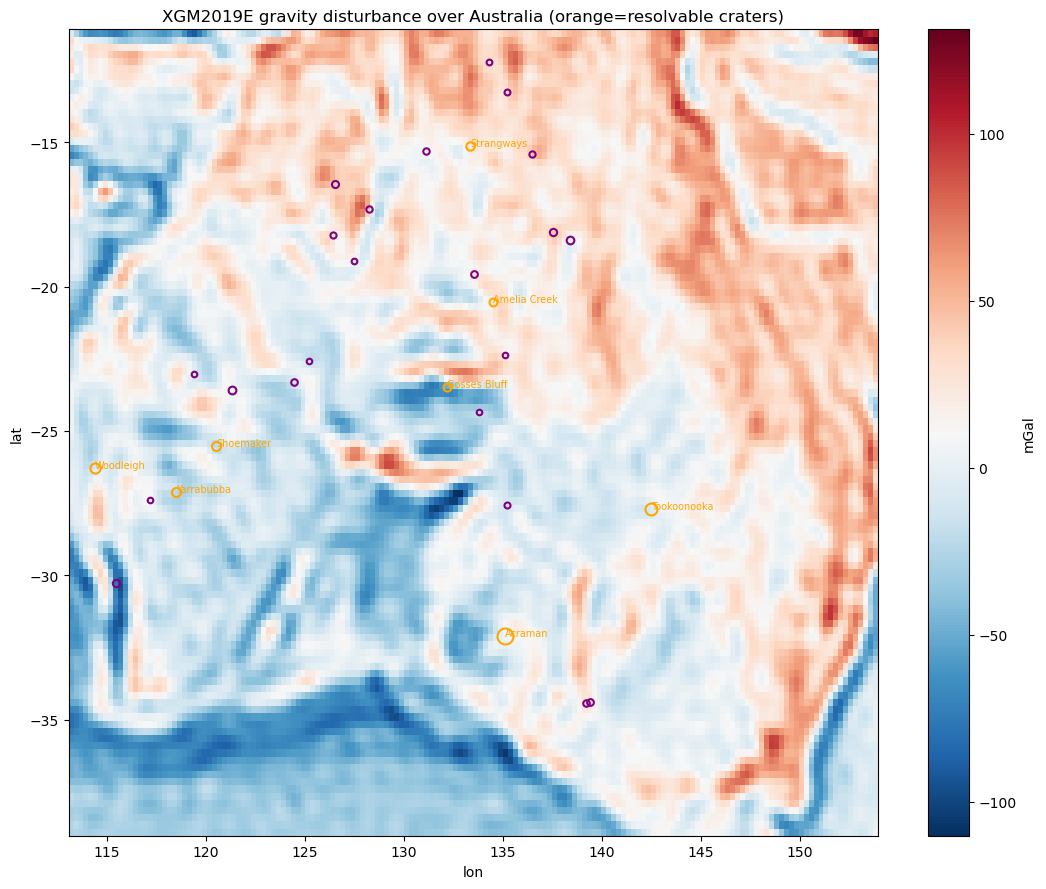

In [11]:
fig, ax = plt.subplots(figsize=(11,9))
iy=np.where((g_lats>=AUS["lat0"])&(g_lats<=AUS["lat1"]))[0]
ix=np.where((g_lons>=AUS["lon0"])&(g_lons<=AUS["lon1"]))[0]
sub=g_field[np.ix_(iy,ix)]
im=ax.pcolormesh(g_lons[ix], g_lats[iy], sub, shading="auto", cmap="RdBu_r")
for name,lat,lon,D,status in kept:
    ax.plot(lon%360, lat, "o", ms=4+D/12,
            mfc="none", mec="orange" if D>=20 else "purple", mew=1.5)
    if D>=20: ax.annotate(name, (lon%360,lat), fontsize=7, color="orange")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
ax.set_title("XGM2019E gravity disturbance over Australia (orange=resolvable craters)")
fig.colorbar(im, label="mGal"); plt.tight_layout(); plt.show()

## 8. Candidate scan — find crater-like locations

Train on resolvable known craters, score a grid across Australia, drop cells near known
craters, and rank. Top cells are candidates to cross-check in QGIS against geology and
the Earth Impact Database.

**Honest caveat:** with few resolvable positives this is suggestive, not conclusive —
the correct framing for a desk study proposing field follow-up.

In [8]:
def scan(step=0.5, dmin=20, top=15):
    sel=[i for i,c in enumerate(kept) if c[3]>=dmin]
    X=np.vstack([Xc[sel],Xk]); y=np.r_[np.ones(len(sel)),np.zeros(len(Xk))]
    rf=RandomForestClassifier(n_estimators=400,max_depth=4,
                              class_weight="balanced",random_state=0).fit(X,y)
    out=[]
    for la in np.arange(AUS["lat0"],AUS["lat1"],step):
        for lo in np.arange(AUS["lon0"],AUS["lon1"],step):
            if all(np.hypot(la-c[1],lo-c[2])>1.0 for c in kept):
                fv=feat_vector(la,lo)
                if fv: out.append((rf.predict_proba([fv])[0,1],la,lo))
    out.sort(reverse=True)
    return out[:top]

print("Top candidate cells (probability, lat, lon) — REAL DATA:")
for p,la,lo in scan():
    print(f"  p={p:.3f}   lat={la:6.1f}  lon={lo:6.1f}")

Top candidate cells (probability, lat, lon) — REAL DATA:
  p=0.545   lat= -13.5  lon= 118.0
  p=0.541   lat= -23.0  lon= 123.0
  p=0.524   lat= -13.0  lon= 115.0
  p=0.522   lat= -21.0  lon= 138.5
  p=0.512   lat= -13.0  lon= 118.0
  p=0.486   lat= -13.0  lon= 113.5
  p=0.472   lat= -13.5  lon= 115.0
  p=0.468   lat= -26.5  lon= 116.5
  p=0.456   lat= -13.0  lon= 118.5
  p=0.452   lat= -25.5  lon= 139.5
  p=0.451   lat= -25.5  lon= 116.0
  p=0.451   lat= -20.5  lon= 138.5
  p=0.449   lat= -31.0  lon= 135.0
  p=0.441   lat= -25.5  lon= 115.5
  p=0.441   lat= -33.0  lon= 141.5


## 9. Next steps
- Raise `lmax` to 720 in cell 3 and re-run for final resolution.
- Take the top candidates into QGIS: overlay geology, rule out plutons/volcanics/salt,
  confirm they are not already in the Earth Impact Database.
- A candidate that is circular in both gravity and magnetic, geologically unexplained,
  and uncatalogued is what justifies a field trip.